# RES-Suppression (20%) Fake Data Study -- Containment Split

Same RES-suppression fake data closure check as `FakeData_InteractionMode_Studies.ipynb`, but for the containment-split (contained/exiting) simultaneous fit. Reads from the `FakeData_InteractionMode_Containment` output directory.

**Baseline to compare against:** the combined-sample study closes after adding a dedicated `NormCCRES` synthetic normalization dial (w(α) = 1 + 0.20·α for CC RES events) -- without it, `MaCCRES`/`MvCCRES` alone can't reproduce a flat 20% rate suppression and the fit doesn't close. With the dial, `NormCCRES` lands at -0.8σ and the signal template parameters flatten back to ~1.0 across all truth bins. See `FakeData_InteractionMode_Studies.ipynb` for that result. This notebook checks whether the same closure holds once the fit is split into the 4-sample containment scheme.

**Binning:** truth binning is the medulla-optimized *combined* dpT binning (`binning_true_dpT.txt`, 6 finite + 1 overflow = 7 bins, shared across all 4 samples). Reco binning is per-channel: contained samples use `binning_reco_dpT_contained.txt` (20 finite + 1 overflow = 21 rows), exiting samples use `binning_reco_dpT_exiting.txt` (10 finite + 1 overflow = 11 rows).

**`cov_bin_range` -- carried over from the Asimov/Q2 containment closure tests, NOT yet re-verified for this run.** Block boundaries in the full 64x64 matrix are at 0, 21, 32, 53, 64 (with-overflow widths); each slice used for chi2 stops one row short of its block boundary to match the category histograms: selection_contained (0,20), selection_exiting (21,31), sideband_contained (32,56), sideband_exiting (57,81) -- the sideband blocks are wider than the selection blocks because the sideband uses its own dedicated 24-finite-bin binning, not the selection's. Since `enablePca: true` reduces parameters based on the actual response matrix, and this RES-suppression weighting could shift bin population differently than the Q2 or Asimov runs, re-check these boundaries against this run's own `covarianceMatrix_TH2D` axis labels before trusting the per-sample chi2 breakdown.

**Not included here:** `FakeData_InteractionMode_Studies.ipynb` has an additional ad-hoc cell doing interaction-mode composition pie charts and stacked δpT histograms directly from the raw ntuple -- exploratory diagnostic content, not reusable template content. Not ported; re-derive directly from the ntuple if needed.


In [14]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Selection - Contained

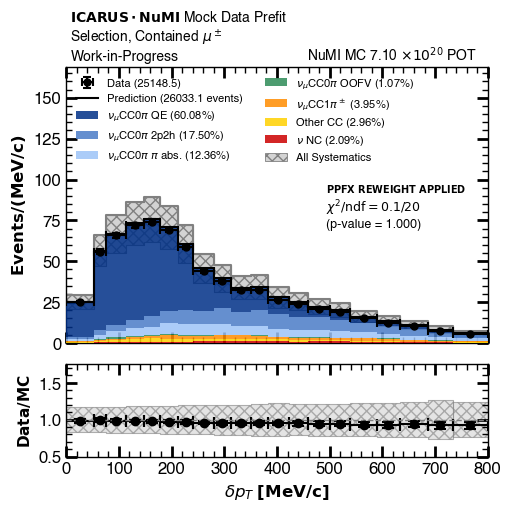

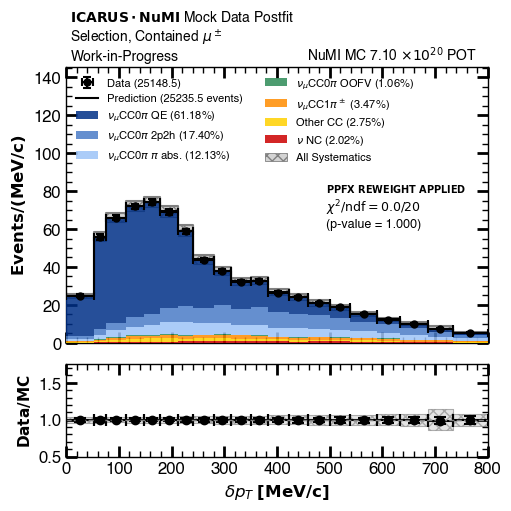

In [15]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/prefit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # block boundaries carried over from Asimov/Q2 containment closures -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Prefits', save_name='prefit_dpT_selection_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/postfit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Postfits', save_name='postfit_dpT_selection_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Selection - Exiting

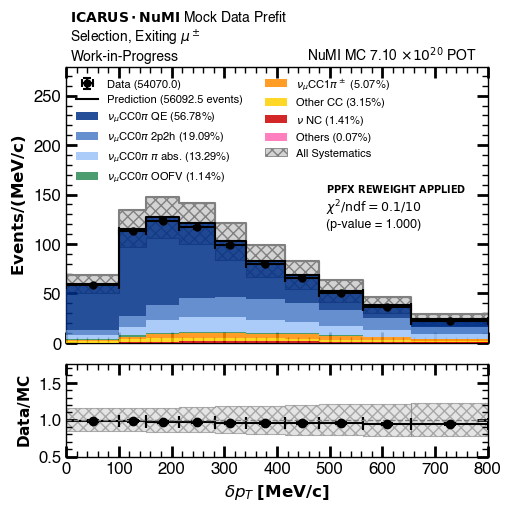

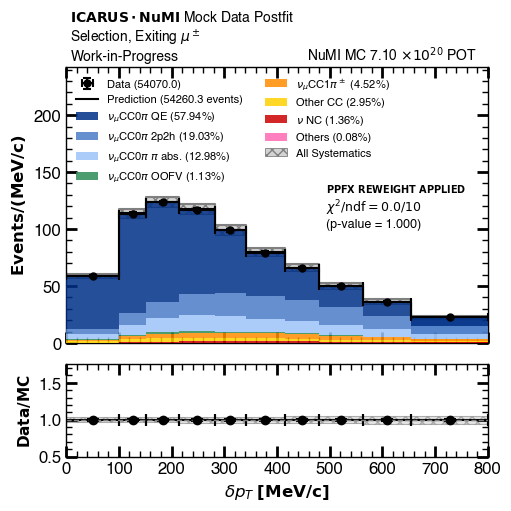

In [16]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/prefit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # block boundaries carried over from Asimov/Q2 containment closures -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Prefits', save_name='prefit_dpT_selection_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/postfit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Postfits', save_name='postfit_dpT_selection_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Sideband - Contained

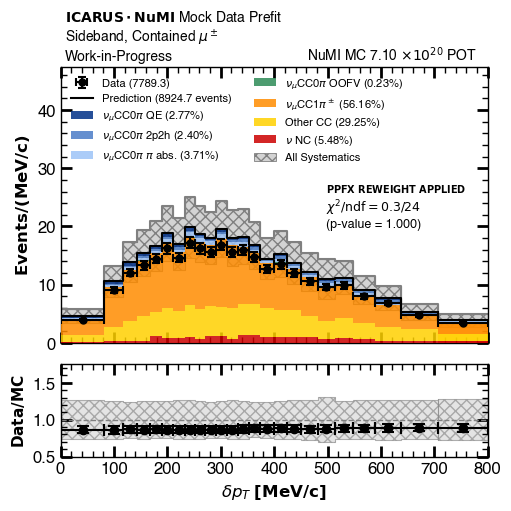

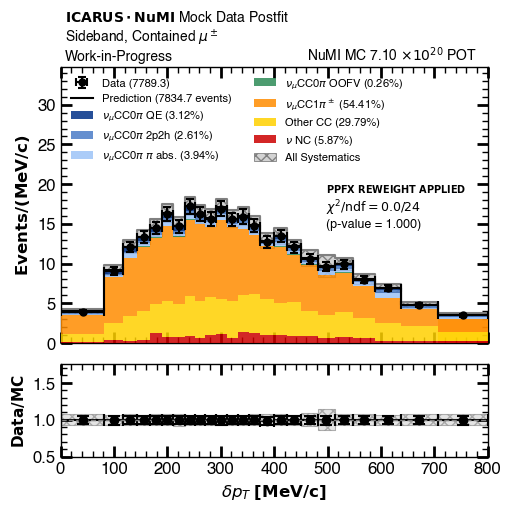

In [17]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/prefit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # block boundaries carried over from Asimov/Q2 containment closures -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Prefits', save_name='prefit_dpT_sideband_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/postfit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Postfits', save_name='postfit_dpT_sideband_contained',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Sideband - Exiting

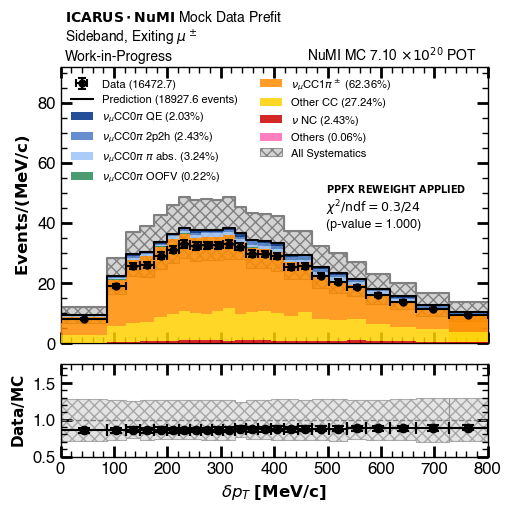

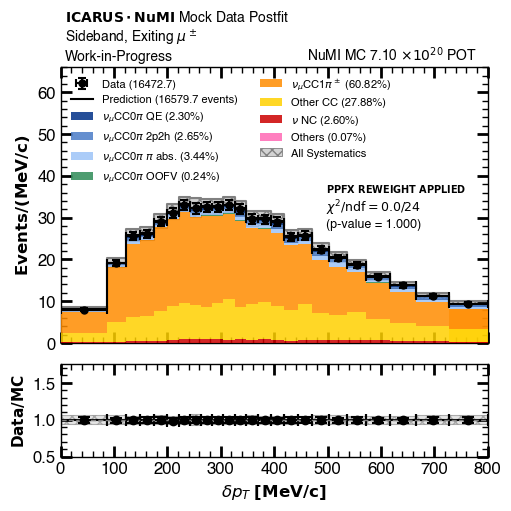

In [18]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/prefit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # block boundaries carried over from Asimov/Q2 containment closures -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Prefits', save_name='prefit_dpT_sideband_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/postfit_fakeData_InteractionMode_dpT_containment.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Mock Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/FakeData_InteractionMode_Containment/Postfits', save_name='postfit_dpT_sideband_exiting',
    pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
)

## Cross-Section Extraction

From `fakeData_InteractionMode_XSec_dpT_containment.root`. Truth-level, 7 truth bins -- unchanged by the reco-level containment split.

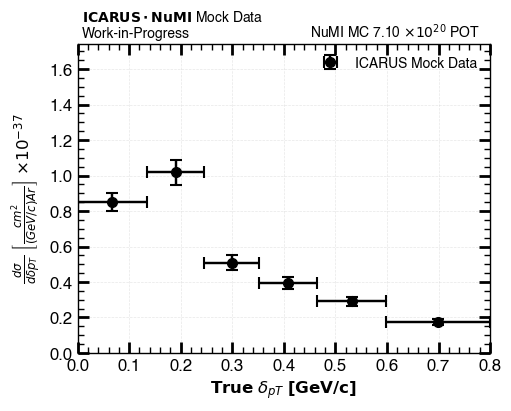

In [19]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_XSec_dpT_containment.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_dpT_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel=r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-37}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Mock Data",
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/dpT/FakeData_InteractionMode_Containment/XSection', 'dpT_XS')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.758637e-01
  0.1350 – 0.2460           1.059684e+00
  0.2460 – 0.3520           5.451330e-01
  0.3520 – 0.4650           4.246163e-01
  0.4650 – 0.5980           3.148177e-01
  0.5980 – 0.8000           1.866928e-01

χ² / Ndof = 3.6 / 6 = 0.594
p-value = 0.736

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT) [RES_0p8]
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.668862e-01
  0.1350 – 0.2460           1.038791e+00
  0.2460 – 0.3520           5.232345e-01
  0.3520 – 0.4650           4.075424e-01
  0.4650 – 0.5980           3.021836e-01
  0.5980 – 0.8000           1.781192e-01

χ² / Ndof = 0.7 / 6 = 0.114
p-value = 0.995


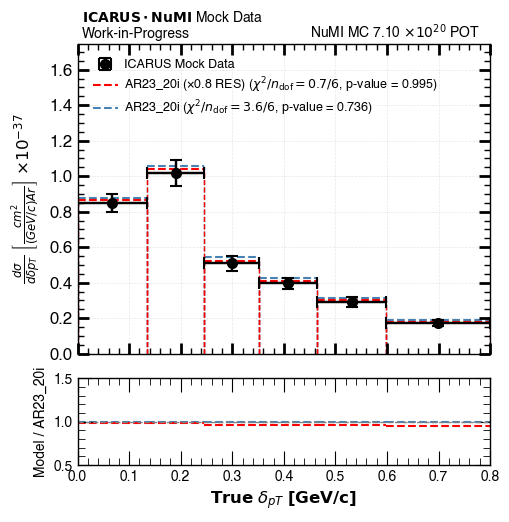

In [20]:
# Scale extracted
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

# Overlay 1: nominal GENIE vs extracted
fig_xs, ax_xs, xsec_nominal, chi2_nominal = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i',
    color='steelblue',
    reweight_mode=None,
    add_ratio=True,
    nominal_label='AR23_20i',
    draw_extracted_ratio=False,
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
)

# Overlay 2: RES-suppressed truth vs extracted
fig_xs, ax_xs, xsec_res, chi2_res = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
    nuisance_var='ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10=1e37,
    label='AR23_20i (\u00d70.8 RES)',
    color='red',
    reweight_mode='RES_0p8',
    add_ratio=True,
    draw_extracted_ratio=False,
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
)
save_fig(fig_xs, r'../Plots/dpT/FakeData_InteractionMode_Containment/XSection', 'dpT_XS_wGENIE')
display(fig_xs)

## Template Parameter Post-fit Values

One set of 7 template parameters, shared across all four samples -- not split by containment.

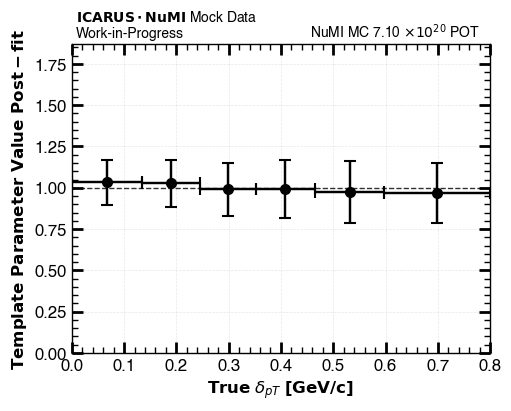

In [21]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dpT_lp_genie/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT'
)
save_fig(fig_template, r'../Plots/dpT/FakeData_InteractionMode_Containment/TemplateParameters', 'dpT')

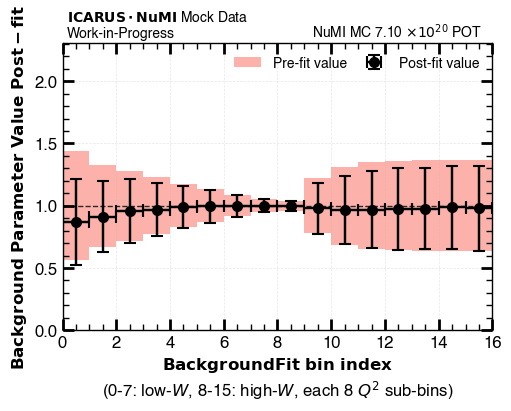

In [22]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dpT/FakeData_InteractionMode_Containment/BackgroundFitParameters', 'dpT')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


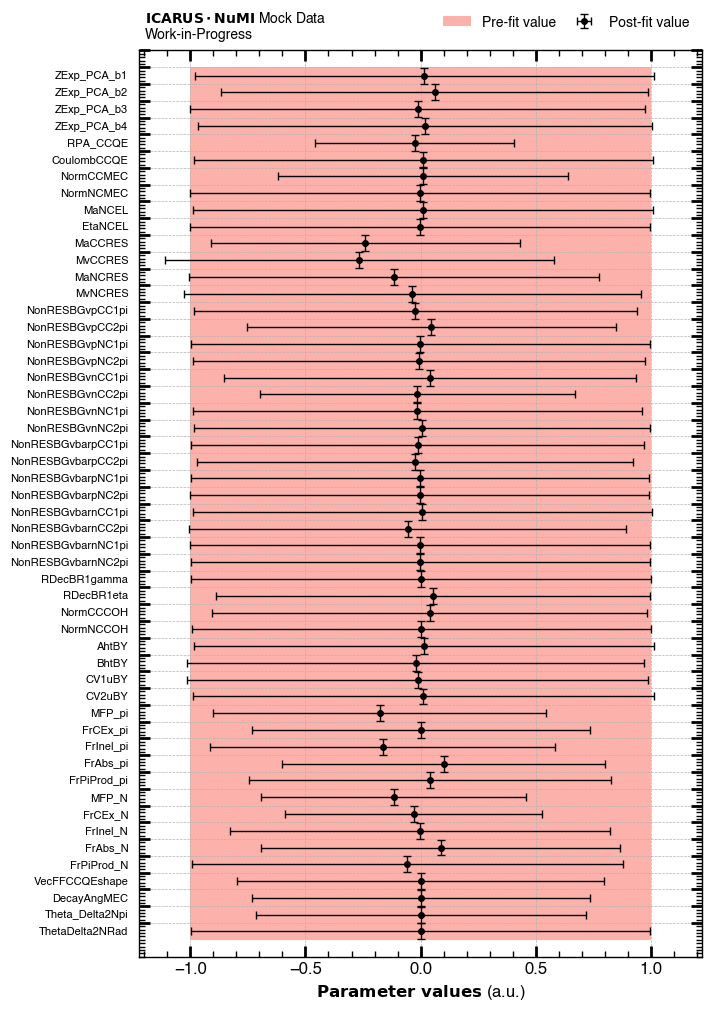

In [23]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_InteractionModel')

Number of parameters: 27


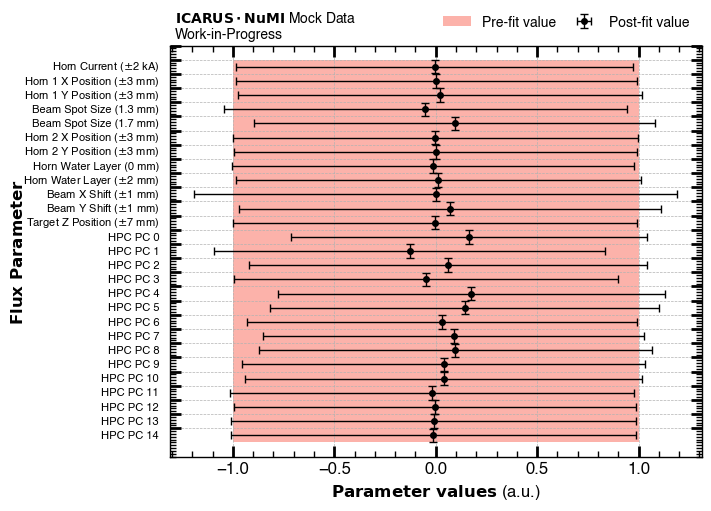

In [24]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_Flux')

Number of parameters: 9


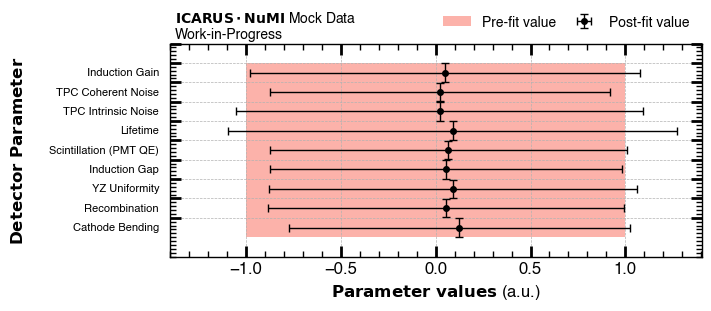

In [25]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_Detector')

Number of parameters: 5


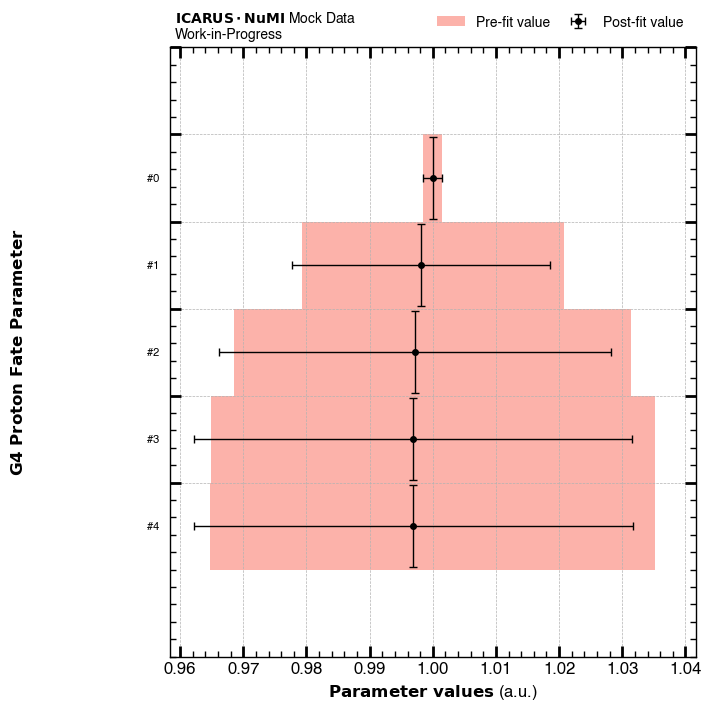

In [26]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_G4_Proton')

Number of parameters: 3


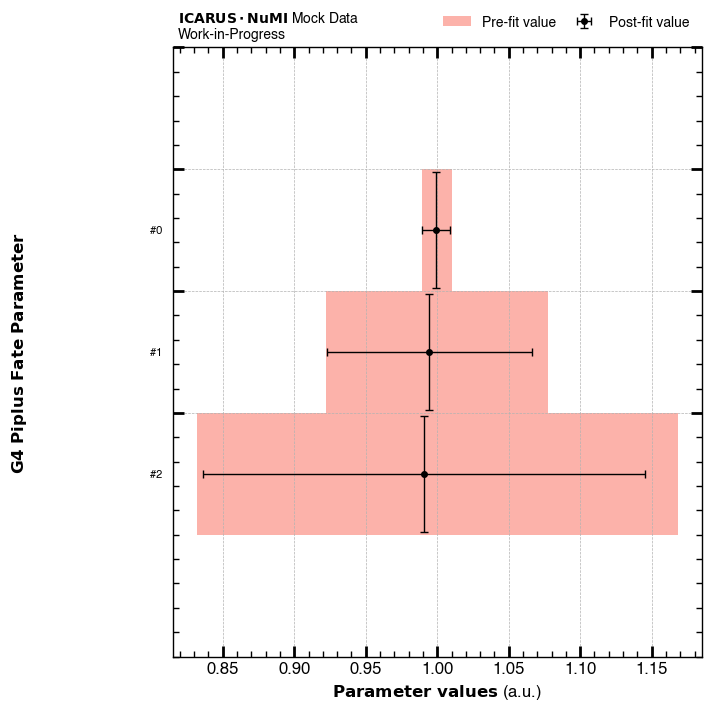

In [27]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_G4_Piplus')

Number of parameters: 3


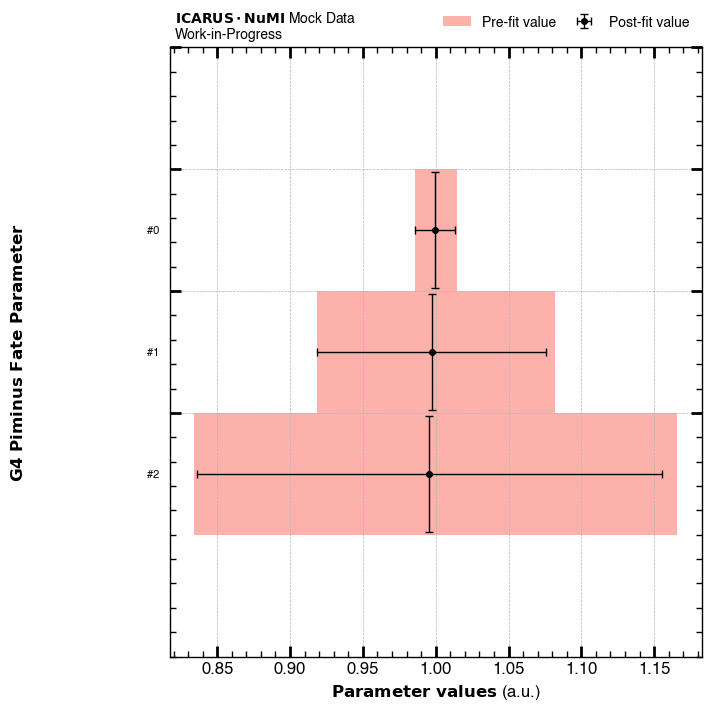

In [28]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/FakeData_InteractionMode_Containment/NuisanceParameters', 'dpT_G4_Piminus')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


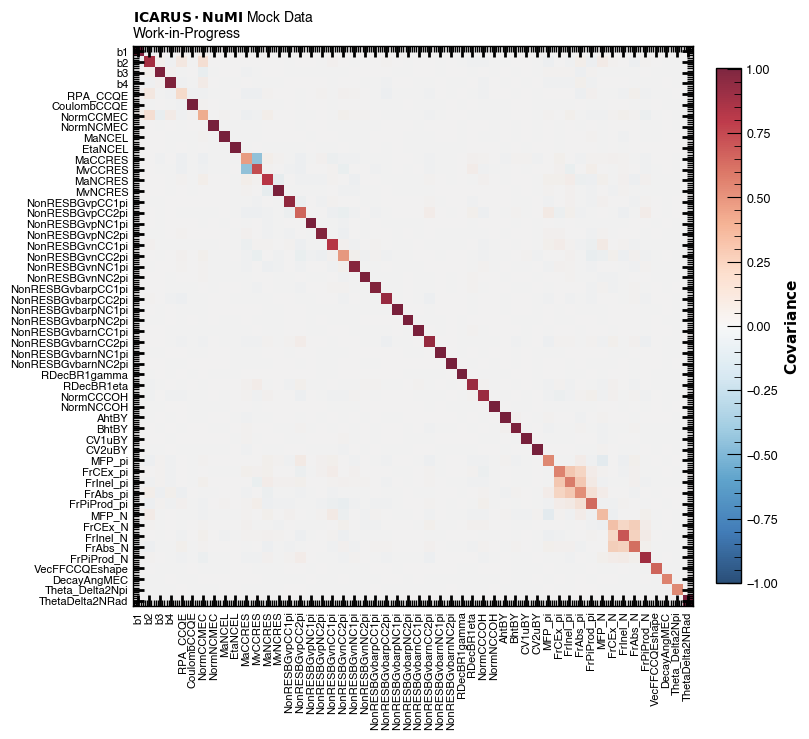

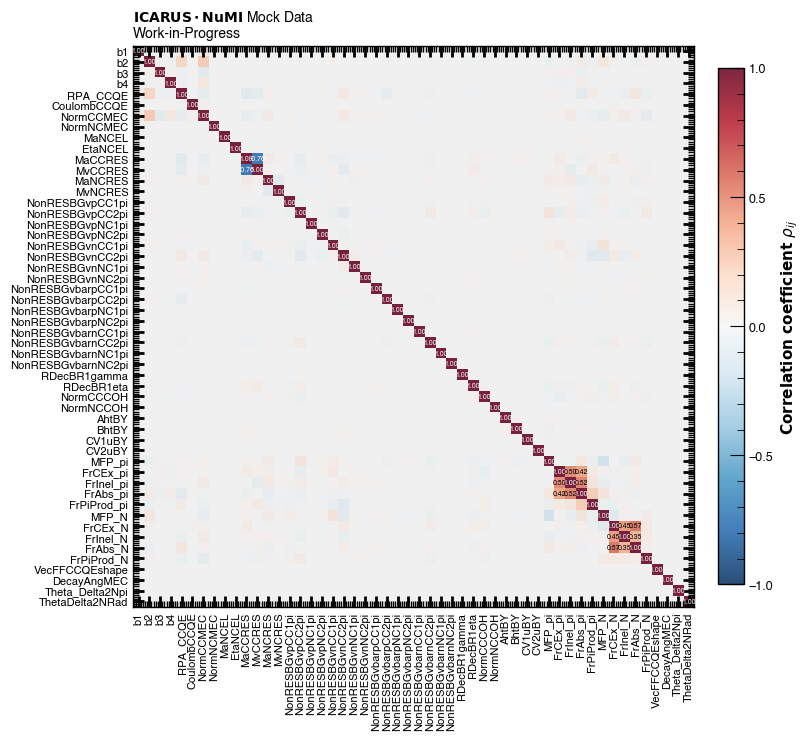

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    figsize=(8, 20),
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


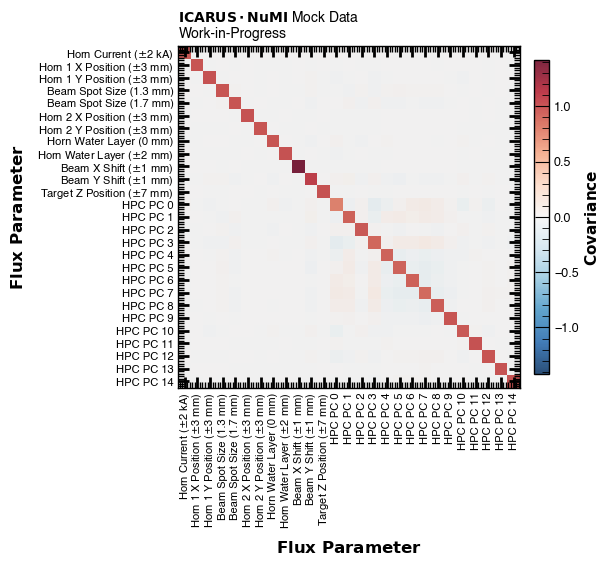

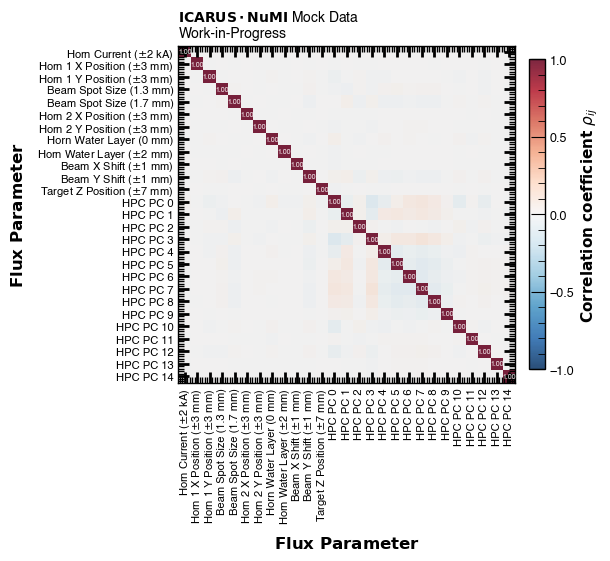

In [30]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


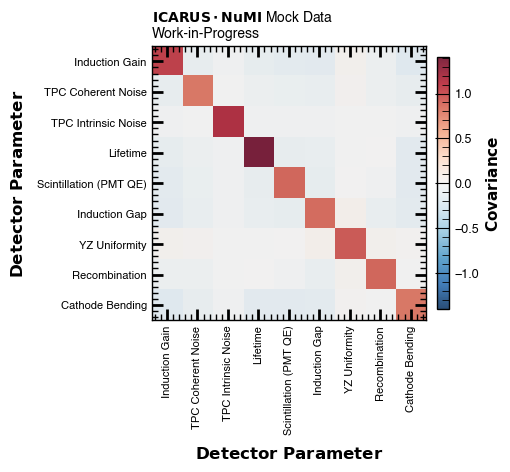

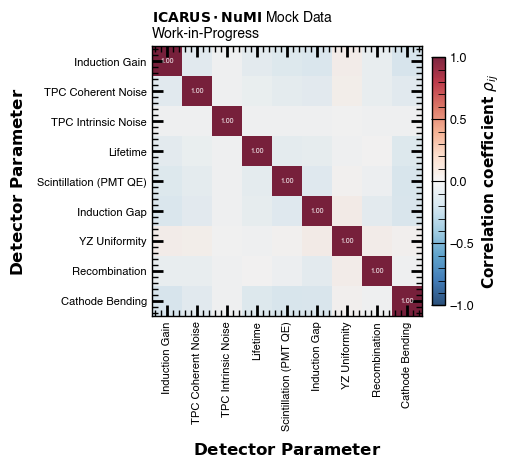

In [31]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/FakeData_InteractionMode_Containment/fakeData_InteractionMode_dpT_containment.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Mock Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/FakeData_InteractionMode_Containment/Postfits', 'detector_param_correlation')